# Lesson 10a: The Atomic Cluster Expansion (ACE)

**What you will learn**

- How the energy of a set of atoms is organized as a **body-order expansion**,
  and why an explicit summation over $K$-body terms costs
  $\mathcal{O}(N_c^{K})$.
- The construct of a **one-particle basis** defined as a radial basis times
  spherical harmonics: $\phi_{nlm}(\vec r) = R_{nl}(r)\,Y^{(l)}_m(\hat r)$.
- The **density trick**: Projecting the neighbor density onto the one-particle
  basis yields the atomic base, $A_{i,nlm}$. The product of atomic bases gives
  the $(\nu+1)$-body descriptors at a linear cost with respect to the number of
  neighbors.
- **Symmetrization**: Contracting the atomic bases with (generalized)
  Clebsch–Gordan couplings yields the rotation- and inversion-invariant
  $B$-basis.
- Why the $B$-basis is **complete** and how **linear ACE** models are built on
  it.
- How ACE relates to **message passing**, which is the bridge to MACE in Lesson
  10b.

**Prerequisites:**

- [Lesson 02b](02b_spherical_harmonics.ipynb): Spherical harmonics,
- [Lessons 03a](03a_tensor_products_theory.ipynb) and
  [03b](03b_tensor_products_e3nn.ipynb): Tensor products and Clebsch–Gordan
  coefficients,
- [Lesson 05b](05b_radial_basis_and_cutoffs.ipynb): Radial bases and cutoffs,
- [Lessons 08a](08a_nequip_theory.ipynb) and [09a](09a_allegro_theory.ipynb):
  NequIP and Allegro, for the comparison in the final section.

In [1]:
import sys; sys.path.insert(0, "..")

import math
import matplotlib.pyplot as plt
import torch
from e3nn import o3

from course_utils.equivariance import assert_model_equivariant, model_equivariance_error
from course_utils.plotting import scene3d, draw_point_cloud, show3d

torch.manual_seed(0)
# This is a theory notebook and the code base is tiny. So, we use float64
# everywhere and the equivariance checks stay within machine precision.
torch.set_default_dtype(torch.float64)
device = "cpu"
print(f"torch {torch.__version__}")

torch 2.7.1+cu126


## The body-order expansion of the energy

The atomic cluster expansion theory (ACE) is based on its classical many-atom
counterpart. Here, the total energy of a system of $N$ atoms is expressed as

$$E = V_0 + \sum_i V^{(1)}(\vec r_i) + \frac{1}{2}\sum_{ij} V^{(2)}(\vec r_i, \vec r_j) + \frac{1}{3!}\sum_{ijk} V^{(3)}(\vec r_i, \vec r_j, \vec r_k) + \cdots$$

where $\vec r_i$ is the position of atom $i$, $V_0$ is a constant, $V^{(1)}$ is
a chemical potential, and the potentials $V^{(2)}, V^{(3)}, \dots$ are symmetric
functions that vanish when two indices coincide. A term $V^{(K)}$, involving $K$
atoms, is called a **$K$-body** term. Regrouping the equation above around each
atom gives the **site energy**,

$$E_i = V^{(1)}(\vec r_i) + \frac{1}{2}\sum_{j} V^{(2)}(\vec r_i, \vec r_j) + \frac{1}{6}\sum_{jk} V^{(3)}(\vec r_i, \vec r_j, \vec r_k) + \cdots$$

with $E = \sum_i E_i$ after absorbing $V_0$. Once a cutoff radius, $r_c$, is
introduced, the sums run over the $N_c$ neighbors of atom $i$. Two factors make
this expansion difficult to use in practice:

1. **Slow convergence**: For bulk metals, terms up to $K > 15$ may be required.
2. **Exponential cost**: The order-$(K+1)$ term is a $K$-fold sum over neighbors
   and costs $\mathcal{O}(N_c^{K})$. With $N_c \approx 10^2$ to $10^3$ in
   close-packed materials, anything beyond $K = 3$ is prohibitive.

The ACE theory removes the second obstacle and helps with the first one by
making high order terms more affordable.

### The environment of atom $i$

The site energy is a function of the environment $\sigma = (\vec r_{i1}, \vec
r_{i2}, \dots)$, and the set of displacement vectors $\vec r_{ij} = \vec r_j -
\vec r_i$ from atom $i$ to its neighbors. $E_i(\sigma)$ must be invariant under
permutations of like neighbors and under the rotations and reflections of
$O(3)$. ACE builds in both types of invariances by construction.

## The one-particle basis $\phi_{nlm}$

ACE expands $E_i(\sigma)$ in products of a complete basis of single-bond
functions $\phi_v(\vec r)$. A **cluster basis function** for a cluster of $K$
bonds is can be expressed as

$$\Phi_{\alpha\boldsymbol\nu} = \phi_{v_1}(\vec r_{ij_1})\,\phi_{v_2}(\vec r_{ij_2})\cdots\phi_{v_K}(\vec r_{ij_K}),$$

where $\alpha = (j_1,\dots,j_K)$ lists the neighbors and $\boldsymbol\nu =
(v_1,\dots,v_K)$ the basis indices. For the single-bond basis, the following
separable product of radial and angular functions can be adopted [[Drautz,
*Phys. Rev. B* **99**, 014104
(2019)](https://doi.org/10.1103/PhysRevB.99.014104)],

$$\phi_v(\vec r) = \sqrt{4\pi}\; R_{nl}(r)\, Y^{(l)}_m(\hat r), \qquad v = (nlm),$$

where, $R_{nl}$ denotes the radial functions and $Y^{(l)}_m$ stands for the
spherical harmonics, $r = |\vec r|$, and $\hat r = \vec r / r$. These are
exactly the objects we introduced in Lessons 02b and 05b. The radial functions
are often built from a polynomial basis functions with a cosine cutoff,

$$g_0 = 1, $$ $$ g_1(r) = 1 + \cos(\pi r / r_c), $$ $$ g_k(r) = \tfrac{1}{4}\big[1 - T_{k-1}(x)\big]\big[1 + \cos(\pi r / r_c)\big] \;\; \qquad (k \ge 2),$$

where $T_k$ are Chebyshev polynomials of the first kind and

$$x(r) = 1 - 2\,\frac{e^{-\lambda (r/r_c - 1)} - 1}{e^{\lambda} - 1},$$

are the rescaling functions (shown as $x$ for brevity), with sharpness $\lambda$
sample small distances more densely. As such, $R_{nl}$ becomes a linear
combination $R_{nl} = \sum_k c_{nlk}\, g_k$. In this lesson, we take $R_{nl} =
g_n$, to make it simpler and independent of $l$. Note that in [Drautz, *Phys.
Rev. B* **99**, 014104 (2019)](https://doi.org/10.1103/PhysRevB.99.014104),
complex spherical harmonics are used while e3nn uses the real ones. We quote the
equations as written there and explicitly state where the $(-1)^m$ structure
matters and how they simplify in the real basis.

Let's implement the radial basis functions in PyTorch

In [2]:
def drautz_radial_basis(r, n_max, r_c, lam=5.0):
    """g_1, ..., g_n_max of Drautz ."""
    
    # Rescaling function
    x = 1 - 2 * ((torch.exp(-lam * (r / r_c - 1)) - 1) / (math.exp(lam) - 1))
    
    # Cosine cutoff
    envelope = (1 + torch.cos(math.pi * r / r_c)) * (r < r_c)
    
    # g_1
    g = [envelope]
    
    # T_0, T_1
    T_prev, T_curr = torch.ones_like(x), x
    
    # Loop over k = 2, ..., n_max
    for k in range(2, n_max + 1):
          
        # g_k uses T_{k-1}
        g.append(0.25 * (1 - T_curr) * envelope)
        
        # Chebyshev recursion
        T_prev, T_curr = T_curr, 2 * x * T_curr - T_prev
        
    # Returns shape (*r.shape, n_max)
    return torch.stack(g, dim=-1)

The implementation allows us to also visualize the radial basis functions

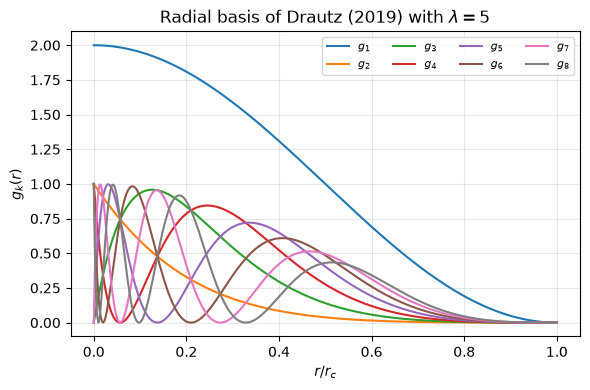

In [3]:
# Set the cutoff radius
r_c = 5.0

# Create a grid of distances up to the cutoff radius
r_grid = torch.linspace(0.0, r_c, 400)

# Compute the radial basis functions for n_max=8
g_plot = drautz_radial_basis(r_grid, n_max=8, r_c=r_c)

# Plot the radial basis functions
fig, ax = plt.subplots(figsize=(6, 4))
for k in range(8):
    ax.plot(r_grid / r_c, g_plot[:, k], label=rf"$g_{{{k + 1}}}$")
ax.set_xlabel(r"$r / r_c$")
ax.set_ylabel(r"$g_k(r)$")
ax.set_title(r"Radial basis of Drautz (2019) with $\lambda = 5$")
ax.legend(ncols=4, fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()

## The density trick: from $\mathcal{O}(N_c^{\nu})$ to $\mathcal{O}(N_c)$

Arguably, the denisty trick is the key insight from the ACE framework. Expanding
$E_i$ in the cluster basis with unrestricted neighbor sums gives,

$$E_i(\sigma) = \sum_j \sum_{v} c^{(1)}_{v}\,\phi_{v}(\vec r_{ij}) + \frac{1}{2}\sum_{j_1 j_2} \sum_{v_1 v_2} c^{(2)}_{v_1 v_2}\, \phi_{v_1}(\vec r_{ij_1})\,\phi_{v_2}(\vec r_{ij_2}) + \frac{1}{3!}\sum_{j_1 j_2 j_3}\sum_{v_1 v_2 v_3} c^{(3)}_{v_1 v_2 v_3}\, \phi_{v_1}(\vec r_{ij_1})\,\phi_{v_2}(\vec r_{ij_2})\,\phi_{v_3}(\vec r_{ij_3}) + \cdots$$

Evaluated naively, the order-$\nu$ term is a $\nu$-fold sum over neighbors with
$N_c^{\nu}$ terms. Defining the **atomic basis**, $A_{iv}$, as the projection of
the basis functions onto the **neighbor density**, $\rho_i$, we can write

$$A_{iv} = \langle \rho_i | \phi_v \rangle = \sum_{j} \phi_v(\vec r_{ij}), $$

where

$$ \rho_i(\vec r) = \sum_j \delta(\vec r - \vec r_{ij}).$$

The atomic basis functions are expressed as a single sum over neighbors, a
**2-body** quantity (center plus one neighbor) which are computed once in
$\mathcal{O}(N_c)$ per basis function. The trick is that the *unrestricted*
$\nu$-fold sums in the site energy expansion above can be reordered, using

$$\sum_{j_1, \dots, j_\nu} \prod_{\xi=1}^{\nu} \phi_{v_\xi}(\vec r_{ij_\xi}) = \prod_{\xi=1}^{\nu} \Big( \sum_{j} \phi_{v_\xi}(\vec r_{ij}) \Big) = \prod_{\xi=1}^{\nu} A_{i v_\xi},$$

to factorize the site energy expansion into a polynomial in $A_{iv}$, with each
set of terms carrying its own summation index as

$$E_i(\sigma) = \sum_{v} c^{(1)}_{v} A_{iv} + \sum_{v_1 \ge v_2} c^{(2)}_{v_1 v_2}\, A_{iv_1} A_{iv_2} + \sum_{v_1 \ge v_2 \ge v_3} c^{(3)}_{v_1 v_2 v_3}\, A_{iv_1} A_{iv_2} A_{iv_3} + \cdots$$

Since the expansion coefficients, $c^{(\nu)}_{v_1 \dots v_\nu}$, are symmetric
with respect to the indices $v_1, \dots, v_\nu$, an *ordered* sum $v_1 \ge v_2
\ge \dots$ already covers every distinct combination of basis functions. The
direction of the ordering is purely conventional: the coefficients and the
product $A_{iv_1} A_{iv_2} \cdots$ are both symmetric. So, both $v_1 \ge v_2 \ge
\dots$ and $v_1 \le v_2 \le \dots$ enumerate the same terms. We follow Drautz's
descending ordering convention for consistency.

Building all atomic basis functions, $A_{iv}$, costs $\mathcal{O}(N_c \,
n_{\text{1p}})$ for $n_{\text{1p}}$ one-particle basis functions, and each
product of $\nu$ basis functions costs $\mathcal{O}(\nu)$, independent of $N_c$.
Therefore, a $(\nu+1)$-body descriptor will cost the same as that of a pair
descriptor. This is why ACE scales linearly with the number of neighbors,
irrespective of the order of the expansion.

The scaling advantage and potential speed-up in ACE's density trick comes at a
cost. Note that the neighbor sums in the first site energy expression above are
*unrestricted*: every index $j_\xi$ runs over all neighbor indices. Thus, the
same neighbor can appear more than once in a product. For the second-order term,
splitting off the terms with $j_1 = j_2$ gives

$$\sum_{j_1, j_2} \phi_{v_1}(\vec r_{ij_1})\,\phi_{v_2}(\vec r_{ij_2}) = \underbrace{\sum_{j_1 \neq j_2} \phi_{v_1}(\vec r_{ij_1})\,\phi_{v_2}(\vec r_{ij_2})}_{\text{genuine 3-body term}} + \underbrace{\sum_{j} \phi_{v_1}(\vec r_{ij})\,\phi_{v_2}(\vec r_{ij})}_{\text{self-interaction}}.$$

The first sum couples the central atom $i$ to two *different* neighbors, which
is the 3-body term of the true many-body expansion. The second sum is the
diagonal term, in which a neighbor effectively interacts with itself. Each tem
in this summation depends on a single bond vector, $\vec r_{ij}$. Therefore, it
only amounts to a 2-body quantity with no counterpart in the original ACE
expression. These **self-interaction** terms are the price of adopting the
density trick. Fortunately, these terms are harmless in practice. A product of
two one-particle functions of the *same* bond, is itself a function of that one
bond. AS such, it can be expanded in the one-particle basis,

$$\phi_{v_1}(\vec r)\,\phi_{v_2}(\vec r) = \sum_{v} a^{v}_{v_1 v_2}\,\phi_v(\vec r),$$

where the expansion coefficients, $a^{v}_{v_1 v_2}$, are fixed numbers. The
expansion is exact for a complete basis and approximate if truncated. Summing
over the neighbor indices turns the diagonal term into $\sum_v a^{v}_{v_1 v_2}\,
A_{iv}$, which has exactly the form of a first-order term. When the model is
fit, its contribution is simply absorbed into the first-order coefficients
$c^{(1)}_v$. The same argument holds at every order: a $\nu$-fold product with
repeated neighbors collapses onto terms of lower order. As a result,
self-interaction terms can change the expansion coefficients, $c^{(\nu)}$, but
cannot change the functions the expansion can represent.

Let's build a toy atomic environment consisting of a central atom and its
neighbors and verify the aforementioned properties of the basis functions,
numerically

In [4]:
# A toy atomic environment: one central atom (origin) + N_neigh neighbors inside r_c.
N_neigh, r_c, n_max, l_max = 10, 5.0, 4, 3

# Create random neighbor positions in 3D space
directions = torch.randn(N_neigh, 3)

# Normalize the directions to unit vectors
directions = directions / directions.norm(dim=-1, keepdim=True)

# Generate random radii for the neighbors within the cutoff radius
# radii in [1.5, 4.5] < r_c
radii = 1.5 + 3.0 * torch.rand(N_neigh, 1)

# Compute the displacement vectors from the central atom to each neighbor
# Displacement vectors r_ij = r_j - r_i
vecs = radii * directions

# Visualize the toy atomic environment in 3D
fig = scene3d()
draw_point_cloud(vecs, fig=fig, color="C0", label="neighbors j")
draw_point_cloud(torch.zeros(1, 3), fig=fig, color="C3", size=12,
                 label="central atom i")
show3d(fig, title=f"Toy environment: {N_neigh} neighbors of atom i")
print("neighbor distances:", radii.squeeze().sort().values.numpy().round(2))

<plotly figure: Toy environment: 10 neighbors of atom i>

neighbor distances: [1.62 2.07 2.27 2.59 3.79 3.84 4.09 4.14 4.46 4.49]


### The atomic base $A_{i,nlm}$ in e3nn

With $v = (nlm)$ and $R_{nl} = g_n$, the atomic basis can be expressed as

$$A_{i,nlm} = \sum_{j} g_n(r_{ij})\, Y^{(l)}_m(\hat r_{ij}),$$

where we drop the constant $\sqrt{4\pi}$ since it can be absorbed into the
coefficients. In e3nn, this translates into a radial basis times spherical
harmonics, summed over neighbors. Since $Y^{(l)}$ has parity $(-1)^l$, the $A$'s
for fixed $n$ carry the irreps $0e + 1o + 2e + 3o$, making the atomic basis
*equivariant*.

In [5]:
# Create a list of angular momenta l = 0, 1, ..., l_max
ls = list(range(l_max + 1))

# Create the irreps for the spherical harmonics Y_lm and the atomic base A_{nlm}
# Y_lm is a spherical harmonic of degree l and order m
# A_{nlm} is the atomic base function for a given n, l, and m

# Parity of Y^(l) is (-1)^l
irreps_Y = o3.Irreps("1x0e+1x1o+1x2e+1x3o")

# n-major layout
irreps_A = o3.Irreps("+".join([str(irreps_Y)] * n_max))

def atomic_base(vecs):
    """A_{nlm} = sum_j g_n(r_j) Y_lm(r_j^)"""
    # Compute the radial basis functions g_n(r_j)
    r = vecs.norm(dim=-1)                                            # (N,)
    g = drautz_radial_basis(r, n_max=n_max, r_c=r_c)                 # (N, n_max)
    
    # Compute the spherical harmonics Y_lm(r_j^)
    Y = o3.spherical_harmonics(ls, vecs, normalize=True,
                               normalization="component")            # (N, 16)
    
    # Sum over neighbors j
    A = torch.einsum("jn,jy->ny", g, Y)
    
    # Returns a flat vector of irreps ``irreps_A`` (n-major: [n=1: 0e+1o+2e+3o,
    # n=2: ..., ...])
    return A.reshape(-1)


# Compute the atomic base A_{nlm} for the toy environment
A = atomic_base(vecs).reshape(n_max, irreps_Y.dim)

# Print the shape of the atomic base and the number of irreps per n
print(f"A-basis: {tuple(A.shape)}  =  (n_max, (l_max+1)^2);  irreps per n: {irreps_Y}")
print("Cost: one pass over", N_neigh, "neighbors --> O(N_c), a 2-body quantity")

A-basis: (4, 16)  =  (n_max, (l_max+1)^2);  irreps per n: 1x0e+1x1o+1x2e+1x3o
Cost: one pass over 10 neighbors --> O(N_c), a 2-body quantity


Any new equivariant object in this course gets an immediate numerical check,
$A(g\,\sigma) = D(g)\,A(\sigma)$ for random elements, $g \in O(3)$. Inversions
are included. Thus, the odd-$l$ channels must flip sign. Translations are not
checked here because the `atomic_base()` takes displacement vectors, $\vec
r_{ij}$, which makes them translation invariant by construction.

In [6]:
assert_model_equivariant(atomic_base, vecs, irreps_A, tol=1e-10, translation=False)

equivariant!  (max error 2.842e-14 over random O(3) elements)


2.842170943040401e-14

### Verifying the density trick factorization numerically

We now check the density trick exactly: explicit double and triple sums over
neighbor pairs and triples must equal products of $A$'s. We also evaluate the
*restricted* sum with $j_1 \ne j_2$, the true pair term, which differs from
$A_{v_1} A_{v_2}$ by exactly the self-interaction diagonal $\sum_j
\phi_{v_1}(\vec r_{ij})\phi_{v_2}(\vec r_{ij})$.

In [15]:
# One-particle basis values phi_{v}(r_ij) for every neighbor
# Shape (N_neigh, # n_v)
r = vecs.norm(dim=-1)

# Compute the one-particle basis values phi_{v}(r_ij) for every neighbor
phi = (drautz_radial_basis(r, n_max, r_c).unsqueeze(-1)
       * o3.spherical_harmonics(ls, vecs, True, normalization="component").unsqueeze(1))

# v = (n, lm) flattened, n_v = 64
phi = phi.reshape(N_neigh, -1)

# A_v = sum_j phi_v
A_flat = phi.sum(dim=0)

# Three arbitrary basis indices (n, lm) flat
v1, v2, v3 = 1, 20, 42

# Compute the explicit double and triple sums over neighbor pairs and triples
explicit_2 = sum(phi[j1, v1] * phi[j2, v2] for j1 in range(N_neigh) for j2 in range(N_neigh))
explicit_3 = sum(phi[j1, v1] * phi[j2, v2] * phi[j3, v3]
                 for j1 in range(N_neigh) for j2 in range(N_neigh) for j3 in range(N_neigh))

print(f"nu=2:  explicit double sum ({N_neigh ** 2} terms)  = {explicit_2: .10e}")
print(f"       A_v1 * A_v2         (2 factors)  = {A_flat[v1] * A_flat[v2]: .10e}\n")
print(f"nu=3:  explicit triple sum ({N_neigh ** 3} terms) = {explicit_3: .10e}")
print(f"       A_v1 * A_v2 * A_v3  (3 factors)  = {A_flat[v1] * A_flat[v2] * A_flat[v3]: .10e}")
assert torch.isclose(explicit_3, A_flat[v1] * A_flat[v2] * A_flat[v3])

# Check the restricted sum over neighbor pairs with j1 != j2
restricted_2 = explicit_2 - (phi[:, v1] * phi[:, v2]).sum() 
print(f"\nrestricted sum (j1 != j2)  = {restricted_2: .10e}"
      "\n-> differs by the self-interaction diagonal, re-absorbed into lower orders")

nu=2:  explicit double sum (100 terms)  = -4.7788231477e-01
       A_v1 * A_v2         (2 factors)  = -4.7788231477e-01

nu=3:  explicit triple sum (1000 terms) = -4.2699067939e-01
       A_v1 * A_v2 * A_v3  (3 factors)  = -4.2699067939e-01

restricted sum (j1 != j2)  = -3.5964693457e-01
-> differs by the self-interaction diagonal, re-absorbed into lower orders


The operation count per descriptor summarizes the argument: the explicit
$\nu$-fold sum grows as $N_c^{\nu}$, whereas the density trick pays $N_c$ once
and then $\nu$ multiplications per descriptor.

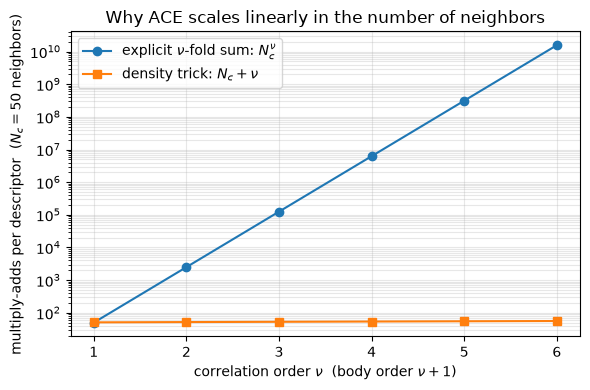

In [ ]:
# Operation-count picture of the density trick (per descriptor of correlation order nu)
nus = torch.arange(1, 7)

# Number of neighbors
N_c = 50

# Compute the explicit cost and density trick cost for different correlation
# orders
# nu-fold explicit neighbor sum
explicit_cost = N_c ** nus.double()

# Build A once (N_c) + nu products
density_cost = N_c + nus.double()

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(nus, explicit_cost, "o-", label=r"explicit $\nu$-fold sum: $N_c^{\nu}$")
ax.semilogy(nus, density_cost, "s-", label=r"density trick: $N_c + \nu$")
ax.set_xlabel(r"correlation order $\nu$  (body order $\nu + 1$)")
ax.set_ylabel(f"multiply-adds per descriptor  ($N_c = {N_c}$ neighbors)")
ax.set_title("Why ACE scales linearly in the number of neighbors")
ax.legend()
ax.grid(alpha=0.3, which="both")
fig.tight_layout()

## Symmetrization: the invariant $B$-basis

The product basis of the form, $A_{iv_1} A_{iv_2} \cdots$, is permutation
invariant (each $A$ is already summed over neighbors) and translation invariant
(built from $\vec r_{ij}$). However, it is not rotation or inversion invariant:
each $A_{i,nlm}$ transforms with the Wigner matrix $D^{(l)}$. Since the energy
must be a scalar, only those combinations of products may appear that can couple
to a total angular momentum of zero. This is the same Clebsch-Gordan machinery
of tensor products described in Lesson 03a. The same approach can be adopted
here to reduce the products of the atomic bases into a set of rotation- and
inversion-invariant descriptors, $B^{(K)}_{i\boldsymbol{nl}}$,

$$B^{(1)}_{in} = A_{in00},$$

$$B^{(2)}_{in_1 n_2 l} = \sum_{m=-l}^{l} (-1)^m\, A_{in_1 l m}\, A_{in_2 l\,{-m}},$$

$$B^{(3)}_{in_1 n_2 n_3\, l_1 l_2 l_3} = \sum_{m_1 m_2 m_3} \begin{pmatrix} l_1 & l_2 & l_3 \\ m_1 & m_2 & m_3 \end{pmatrix} A_{in_1 l_1 m_1} A_{in_2 l_2 m_2} A_{in_3 l_3 m_3},$$

with the Wigner $3j$ symbol in the last line. For higher tensor orders,
generalized Clebsch-Gordan couplings (iterated pairwise contractions) can play a
similar role. Two selection rules follow from Lesson 03a:

- **Rotation invariance**: The coupled $l$'s must be able to reach total $L =
  0$. That is, $l_1 = l_2$ for $B^{(2)}$ and the triangle rule $|l_1 - l_2| \le
  l_3 \le l_1 + l_2$ for $B^{(3)}$.
- **Inversion invariance**: Since $Y^{(l)}$ has parity $(-1)^l$, only couplings
  with even $l_1 + l_2 + \dots$ give true scalars ($0e$). Odd sums give
  pseudo-scalars ($0o$), which Drautz excludes for $K \ge 3$.

The complete invariant expansion of the site energy can then be written in a
compact notation as

$$E_i(\sigma) = \sum_{K}\sum_{\boldsymbol{nl}} c^{(K)}_{\boldsymbol{nl}}\, B^{(K)}_{i\boldsymbol{nl}}.$$

It is important to note that using the e3nn's real spherical harmonics, the
second-order contraction becomes a plain dot product, $B^{(2)}_{in_1n_2l} =
\sum_m A_{in_1lm} A_{in_2lm}$ up to normalization factor, and `o3.wigner_3j`
supplies the real-basis $3j$ tensor for the third-order contraction. 

In [ ]:
# (n_max, 16), slices per l below
A = atomic_base(vecs).reshape(n_max, -1)

# Y^(l) occupies indices l^2 ... (l+1)^2-1
sl = {l: slice(l * l, (l + 1) * (l + 1)) for l in ls}

# B1: the l = 0 channel of A
# Shape (n_max,)
B1 = A[:, sl[0]].squeeze(-1)

# B2: dot product over m within each l channel
# Example: n1, n2 summed, l = 2
B2 = torch.einsum("nm,pm->", A[:, sl[2]], A[:, sl[2]])

# B3: real Wigner-3j contraction, (l1, l2, l3) = (1, 1, 2)
w3j_112 = o3.wigner_3j(1, 1, 2)
B3 = torch.einsum("abc,a,b,c->", w3j_112, A[0, sl[1]], A[1, sl[1]], A[2, sl[2]])

print(f"B1 (2-body invariants, one per n): {B1.numpy().round(4)}")
print(f"B2 (a 3-body invariant, l=2):      {B2:.6f}")
print(f"B3 (a 4-body invariant, 112):      {B3:.6f}")

B1 (2-body invariants, one per n): [5.8217 0.3167 1.087  1.8856]
B2 (a 3-body invariant, l=2):      115.186725
B3 (a 4-body invariant, 112):      0.701822


Let's bundle a few $B$'s into one function of the neighbor vectors and verify
that they are unchanged under random rotations and inversions. In other words,
they are genuine `0e` outputs.

In [ ]:
def B_invariants(vecs):
    """A handful of B-basis invariants of the environment: irreps = "7x0e"."""
    
    # Compute the atomic base functions for the given vectors
    A = atomic_base(vecs).reshape(n_max, -1)
    
    # Compute the B-basis invariants from the atomic base
    # 4 invariants
    B1 = A[:, sl[0]].squeeze(-1)
    
    # l = 1 (odd l is fine: ...
    B2_l1 = torch.einsum("m,m->", A[0, sl[1]], A[1, sl[1]]).reshape(1)
    
    #  ... l1 + l2 = 2l is even)
    B2_l2 = torch.einsum("m,m->", A[0, sl[2]], A[1, sl[2]]).reshape(1)
    
    # B3: real Wigner-3j contraction, (l1, l2, l3) = (1, 1, 2)
    B3 = torch.einsum("abc,a,b,c->", w3j_112,
                      A[0, sl[1]], A[1, sl[1]], A[2, sl[2]]).reshape(1)
    
    # Concatenate all the B-basis invariants into a single tensor
    return torch.cat([B1, B2_l1, B2_l2, B3])


# Check that the B-basis invariants are indeed invariant under random rotations
# and inversions
assert_model_equivariant(B_invariants, vecs, "7x0e", tol=1e-10, translation=False)

equivariant!  (max error 2.665e-15 over random O(3) elements)


2.6645352591003757e-15

**The parity rule in action.** The coupling $(l_1, l_2, l_3) = (1, 1, 1)$
satisfies the triangle rule but has odd $l_1 + l_2 + l_3 = 3$. The real $3j$
tensor for $(1,1,1)$ is the Levi-Civita symbol, so the contraction is a triple
product: a **pseudo-scalar** that passes the $0o$ check and fails the $0e$
check. ACE excludes such couplings for energies, but they are exactly what a
chiral (parity-odd) target needs, as in the Tetris example of
[Lesson 06b](06b_tetris_end_to_end.ipynb).

In [11]:
w3j_111 = o3.wigner_3j(1, 1, 1)


def B3_111(vecs):
    A = atomic_base(vecs).reshape(n_max, -1)
    return torch.einsum("abc,a,b,c->", w3j_111,
                        A[0, sl[1]], A[1, sl[1]], A[2, sl[1]]).reshape(1)


# direct look: inversion of the environment flips the sign
print(f"B3(1,1,1) of  sigma: {B3_111(vecs).item(): .6f}")
print(f"B3(1,1,1) of -sigma: {B3_111(-vecs).item(): .6f}   (pseudo-scalar!)\n")

err_as_scalar = model_equivariance_error(B3_111, vecs, "0e", n_trials=10, translation=False)
err_as_pseudo = model_equivariance_error(B3_111, vecs, "0o", n_trials=10, translation=False)
print(f"checked as a scalar     0e: max error {err_as_scalar:.3e}  <- NOT invariant")
print(f"checked as pseudo-scalar 0o: max error {err_as_pseudo:.3e}  <- equivariant")
assert err_as_scalar > 1e-3 and err_as_pseudo < 1e-10

B3(1,1,1) of  sigma: -0.001580
B3(1,1,1) of -sigma:  0.001580   (pseudo-scalar!)

checked as a scalar     0e: max error 3.160e-03  <- NOT invariant
checked as pseudo-scalar 0o: max error 4.857e-17  <- equivariant


## Completeness and linear ACE models

How much can the basis $\{B^{(K)}\}$ express? Dusson et al. (2022) made the
answer precise:

- **Completeness.** The symmetrized products of the atomic base span the space
  of smooth, permutation- and isometry-invariant functions of the environment.
  Any such function, in particular the site energy, can be approximated to
  arbitrary accuracy by the linear combination of Eq. (34). Dusson et al. also
  give an offline procedure that removes linear dependencies among the
  couplings, so that a genuine basis rather than a spanning set is obtained.
- **Efficiency.** A recursive evaluation scheme (a directed acyclic graph over
  the products, their Sec. 4.3) further reduces the cost of evaluating all
  $B$'s.
- **Stability.** They analyze the conditioning of the resulting least-squares
  problem, the practical bottleneck of linear models, and the need for
  regularization (their Sec. 6).

A **linear ACE potential** is then simply

$$E_i = \sum_{K, \boldsymbol{nl}} c^{(K)}_{\boldsymbol{nl}} B^{(K)}_{i\boldsymbol{nl}},$$

fit by regularized linear least squares to reference energies and forces.
Because the model is linear, the fit is convex and fast, uncertainty
quantification is easy, and the body order of every term is explicit. This
interpretability is a hallmark of ACE. Nonlinear extensions, such as the
Finnis–Sinclair-style square root of a second ACE channel in Drautz Sec. V
(compare his Eq. (3)), and learnable radial functions recover much of the
flexibility of neural networks while keeping the body-ordered structure. The
`pacemaker` and `ACE1.jl` codes implement this pipeline.

**What ACE does not have:** learned features, message passing, or chemical
element embeddings. For $S$ chemical species the coupled basis grows like
$S^\nu$; Lesson 10b shows how MACE fixes this with learned element channels.

## Connection to message passing

At first sight ACE (a descriptor plus linear regression) and equivariant GNNs
such as NequIP (learned message passing) look like different species. They are
not.

Nigam et al. (2022) formalize this with **atom-centered density correlations**
(ACDC): $\nu$-point correlations of the neighbor density $\rho_i$, which are
exactly our $\nu$-fold products of $A$'s symmetrized as in the previous
section, "provide a complete linear basis to expand any property" of an atomic
environment. They then generalize the construction to correlations involving
**multiple centers** and show that message passing corresponds to such
multi-centered density correlations: a message from $j$ to $i$ carries a
symmetrized density expansion centered on $j$, re-expanded around $i$. In this
language:

| | body order per site | centers | features |
|---|---|---|---|
| **ACE** | arbitrary $\nu + 1$, in one shot | 1 (strictly local, radius $r_c$) | fixed basis, linear readout |
| **2-body MPNN** (SchNet, NequIP) | grows by one per layer, implicitly through the nonlinearities | $T$ layers give a receptive field of $T r_c$ | learned, nonlinear |

The two mechanisms are orthogonal axes of a single design space: (i) the
correlation order $\nu$ built *within* a layer and (ii) the number of
message-passing iterations $T$ that propagate information *between* centers.
NequIP sits at $(\nu = 1,\, T \approx 5)$ and classical ACE at $(\nu$ large$,\,
T = 1)$. What lives in between is **MACE** with $(\nu = 3,\, T = 2)$: an ACE
expansion used as the message function of an equivariant MPNN. That is Lesson
10b.

## Summary

In this lesson, we have learned:

- The site energy admits a **body-order expansion** (Drautz Eqs. (1)–(2)), and
  the naive evaluation of a $(\nu+1)$-body term costs $\mathcal{O}(N_c^\nu)$.
- ACE expands $E_i$ in products of a **one-particle basis** $\phi_{nlm} =
  R_{nl}\,Y^{(l)}_m$ (Eq. (20)), a radial basis times spherical harmonics.
- The **density trick** (Eqs. (17)–(19)): the atomic base $A_{i,nlm} = \sum_j
  \phi_{nlm}(\vec r_{ij})$ is computed once in $\mathcal{O}(N_c)$, and
  unrestricted $\nu$-fold neighbor sums factorize into products $\prod_\xi
  A_{iv_\xi}$, which makes high body orders essentially free.
  Self-interactions are absorbed into lower-order coefficients.
- **Symmetrization** with (generalized) Clebsch–Gordan couplings gives the
  invariant $B$-basis (Eqs. (28)–(30)); parity demands an even $\sum_\xi
  l_\xi$. We verified invariance to $\sim 10^{-14}$ and exhibited a
  pseudo-scalar counterexample.
- The $B$-basis is **complete** (Dusson et al.), so a **linear ACE** model
  $E_i = \sum c\,B$ is a convex fit with explicit body order.
- ACE and message passing are two axes of one design space (Nigam et al.).

**Next:** In [Lesson 10b](10b_mace_theory.ipynb), we study MACE, which
occupies the middle of that design space with higher-order equivariant message
passing.

## Exercises

**1. Parity of $B^{(2)}$ with odd $l$ (Difficulty: 🌶️):** $B^{(2)}$ contracts
two factors with the same $l$, so its parity is $(-1)^l (-1)^l = +1$ even for
odd $l$. Verify numerically that the $l = 3$ pair invariant $\sum_m A_{n_1 3 m}
A_{n_2 3 m}$ is unchanged under inversion of the environment, $\vec r_{ij} \to
-\vec r_{ij}$.

<details><summary>Solution</summary>

```python
def B2_l3(vecs):
    A = atomic_base(vecs).reshape(n_max, -1)
    return torch.einsum("m,m->", A[0, sl[3]], A[1, sl[3]]).reshape(1)

print(B2_l3(vecs), B2_l3(-vecs))                 # identical
assert_model_equivariant(B2_l3, vecs, "0e", tol=1e-10, translation=False)
```

Each $A_{n3m}$ flips sign under inversion because $Y^{(3)}$ has parity $(-1)^3
= -1$, and the product of two sign flips is $+1$.
</details>

**2. All allowed $B^{(3)}$ couplings up to $l_{\max} = 2$ (Difficulty: 🌶️🌶️):**
Enumerate all triples $(l_1 \le l_2 \le l_3)$ with $l_i \le 2$ that satisfy
both the triangle rule and the parity rule ($l_1 + l_2 + l_3$ even). Build each
$B^{(3)}$ with `o3.wigner_3j`, using the radial indices $(n_1, n_2, n_3) = (1,
2, 3)$, and verify the invariance of the whole vector.

<details><summary>Solution</summary>

```python
triples = [(l1, l2, l3)
           for l1 in range(3) for l2 in range(l1, 3) for l3 in range(l2, 3)
           if abs(l1 - l2) <= l3 <= l1 + l2 and (l1 + l2 + l3) % 2 == 0]
print(triples)   # [(0, 0, 0), (0, 1, 1), (0, 2, 2), (1, 1, 2), (2, 2, 2)]

def B3_all(vecs):
    A = atomic_base(vecs).reshape(n_max, -1)
    return torch.stack([
        torch.einsum("abc,a,b,c->", o3.wigner_3j(l1, l2, l3),
                     A[0, sl[l1]], A[1, sl[l2]], A[2, sl[l3]])
        for l1, l2, l3 in triples])

assert_model_equivariant(B3_all, vecs, f"{len(triples)}x0e", tol=1e-10, translation=False)
```

Five of the ten ordered triples survive. The triangle rule removes $(0,0,1)$,
$(0,0,2)$ and $(0,1,2)$; the parity rule removes $(1,1,1)$ and $(1,2,2)$.
</details>

**3. The density trick at order $\nu = 4$ (Difficulty: 🌶️🌶️):** Verify
numerically that the explicit quadruple neighbor sum of
$\phi_{v_1}\phi_{v_2}\phi_{v_3}\phi_{v_4}$ equals $A_{v_1}A_{v_2}A_{v_3}A_{v_4}$,
and count the scalar multiplications each side performs for $N_c = 10$
neighbors.

<details><summary>Solution</summary>

```python
v4 = (5, 20, 42, 60)
explicit = phi[:, v4[0]].reshape(-1, 1, 1, 1) * phi[:, v4[1]].reshape(1, -1, 1, 1) \
         * phi[:, v4[2]].reshape(1, 1, -1, 1) * phi[:, v4[3]].reshape(1, 1, 1, -1)
print(explicit.sum().item(), A_flat[list(v4)].prod().item())   # agree to round-off
```

The explicit sum performs $3 N_c^4 = 30{,}000$ multiplications. The density
trick reuses the four $A$'s, which cost $\mathcal{O}(N_c)$ once and are shared
by *all* descriptors, and then needs only 3.
</details>

## References

- [Drautz, *Phys. Rev. B* **99**, 014104 (2019)](https://doi.org/10.1103/PhysRevB.99.014104)
- [Dusson et al., *J. Comput. Phys.* **454**, 110946 (2022)](https://doi.org/10.1016/j.jcp.2022.110946)
- [Nigam et al., *J. Chem. Phys.* **156**, 204115 (2022)](https://doi.org/10.1063/5.0087042)